# 🧪 Pesticidas, fertilizantes y agricultura ecológica en la UE (2011-2024)

La estrategia europea **De la granja a la mesa** fija tres objetivos para 2030:

- reducir un **50 %** el uso y el riesgo de los pesticidas químicos (respecto a la media 2015-2017),
- reducir un **20 %** el uso de fertilizantes,
- alcanzar un **25 %** de superficie agraria ecológica.

Este notebook responde a cinco preguntas con datos oficiales de **Eurostat**:

1. ¿Cómo han evolucionado las ventas de pesticidas en la UE y en España, en total y por tipo?
2. ¿Cómo ha evolucionado el consumo de fertilizantes minerales (nitrógeno y fósforo)?
3. ¿Qué países tienen mayor exceso de nitrógeno por hectárea?
4. ¿Los países con más superficie ecológica venden menos pesticidas por hectárea?
5. Al ritmo actual, ¿van la UE y España camino del objetivo de −50 % de pesticidas en 2030?

Los datos se descargan, limpian y cargan en SQLite con los scripts de `scripts/` (o todo junto con `python main.py`).
Aquí se ejecutan las consultas de `sql/02_consultas_analisis.sql` **por su nombre**: primero se muestra el SQL y después el resultado.

## 0. Preparación

In [1]:
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# Rutas del proyecto (el notebook está en la carpeta notebooks/)
CARPETA_PROYECTO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ARCHIVO_BD = CARPETA_PROYECTO / "database" / "pesticidas_fertilizantes.db"
ARCHIVO_CONSULTAS = CARPETA_PROYECTO / "sql" / "02_consultas_analisis.sql"
CARPETA_OUTPUT = CARPETA_PROYECTO / "data" / "output"
CARPETA_IMAGENES = CARPETA_PROYECTO / "images"
CARPETA_OUTPUT.mkdir(parents=True, exist_ok=True)
CARPETA_IMAGENES.mkdir(parents=True, exist_ok=True)

conexion = sqlite3.connect(ARCHIVO_BD)

# Formato de las tablas: separador de miles y sin decimales innecesarios
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)

In [2]:
def cargar_consultas(ruta):
    """Lee el archivo .sql y devuelve un diccionario {nombre: sql}.
    Cada consulta empieza con una línea '-- nombre: ...'."""
    texto = ruta.read_text(encoding="utf-8")
    bloques = re.split(r"^-- nombre: ", texto, flags=re.MULTILINE)[1:]
    consultas = {}
    for bloque in bloques:
        nombre, sql = bloque.split("\n", 1)
        consultas[nombre.strip()] = sql.strip()
    return consultas


def ejecutar(nombre, mostrar_sql=True):
    """Muestra el SQL de una consulta, la ejecuta y guarda el resultado en data/output/."""
    sql = consultas[nombre]
    if mostrar_sql:
        display(Markdown(f"**Consulta `{nombre}`**\n```sql\n{sql}\n```"))
    resultado = pd.read_sql(sql, conexion)
    resultado.to_csv(CARPETA_OUTPUT / f"{nombre}.csv", index=False, encoding="utf-8")
    return resultado


consultas = cargar_consultas(ARCHIVO_CONSULTAS)
print(f"{len(consultas)} consultas cargadas:")
for nombre in consultas:
    print(" -", nombre)

12 consultas cargadas:
 - 01_pesticidas_total_ue_espana
 - 02_pesticidas_ue_por_grupo
 - 03_pesticidas_espana_por_grupo
 - 04_cambio_por_grupo_espana
 - 05_fertilizantes_ue_espana
 - 06_ranking_exceso_nitrogeno
 - 07_ecologico_vs_pesticidas
 - 08_base_proyeccion_ventas
 - 09_indicador_riesgo_ue_espana
 - 10_ranking_reduccion_riesgo
 - 11_riesgo_por_grupo_ue
 - 12_cobertura_datos_pesticidas


In [3]:
# Estilo común de los gráficos
AZUL_UE = "#2a78d6"       # la UE siempre en azul
NARANJA_ES = "#eb6834"    # España siempre en naranja
COLORES_GRUPOS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # orden fijo para 4 series
GRIS = "#8a8984"

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def guardar_grafico(fig, nombre):
    fig.savefig(CARPETA_IMAGENES / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Ventas de pesticidas en la UE y en España

Eurostat **no publica un total de la UE** para las ventas de pesticidas, y varios países tienen años confidenciales.
Para que la serie sea comparable año a año, el "total UE" es la **suma de los 18 países con la serie completa 2011-2024**
(se calculan con `GROUP BY ... HAVING COUNT(kg) = 14`). Polonia, Bulgaria, Suecia o Eslovaquia quedan fuera por tener años confidenciales
(ver el apartado de limitaciones).

In [4]:
ventas = ejecutar("01_pesticidas_total_ue_espana")
ventas

**Consulta `01_pesticidas_total_ue_espana`**
```sql
-- Pregunta 1. Ventas totales de pesticidas en la UE (países con serie completa)
-- y en España, con variación anual (LAG) e índice 2011 = 100 (FIRST_VALUE).
WITH paises_serie_completa AS (
    SELECT codigo_pais
    FROM fact_ventas_pesticidas
    WHERE codigo_pesticida = 'TOTAL'
    GROUP BY codigo_pais
    HAVING COUNT(kg) = 14              -- COUNT(kg) no cuenta los NULL (confidenciales)
),
total_ue AS (
    SELECT v.año, COUNT(*) AS num_paises, SUM(v.kg) AS kg_ue
    FROM fact_ventas_pesticidas AS v
    JOIN paises_serie_completa  AS c ON c.codigo_pais = v.codigo_pais
    WHERE v.codigo_pesticida = 'TOTAL'
    GROUP BY v.año
),
espana AS (
    SELECT año, kg AS kg_espana
    FROM fact_ventas_pesticidas
    WHERE codigo_pesticida = 'TOTAL' AND codigo_pais = 'ES'
)
SELECT
    u.año,
    u.num_paises,
    ROUND(u.kg_ue / 1e6, 2)                                                          AS millones_kg_ue,
    ROUND(100.0 * u.kg_ue / FIRST_VALUE(u.kg_ue) OVER (ORDER BY u.año), 1)           AS indice_ue_2011,
    ROUND(e.kg_espana / 1e6, 2)                                                      AS millones_kg_espana,
    ROUND(100.0 * (e.kg_espana - LAG(e.kg_espana) OVER (ORDER BY u.año))
          / LAG(e.kg_espana) OVER (ORDER BY u.año), 1)                               AS var_anual_espana_pct,
    ROUND(100.0 * e.kg_espana / FIRST_VALUE(e.kg_espana) OVER (ORDER BY u.año), 1)   AS indice_espana_2011,
    ROUND(100.0 * e.kg_espana / u.kg_ue, 1)                                          AS cuota_espana_pct
FROM total_ue AS u
JOIN espana   AS e ON e.año = u.año
ORDER BY u.año;
```

,año,num_paises,millones_kg_ue,indice_ue_2011,millones_kg_espana,var_anual_espana_pct,indice_espana_2011,cuota_espana_pct
0,2011,18,332.37,100.0,73.11,NaN,100.0,22.0
1,2012,18,317.45,95.5,63.49,-13.2,86.8,20.0
2,2013,18,317.75,95.6,71.45,12.5,97.7,22.5
3,2014,18,335.47,100.9,78.82,10.3,107.8,23.5
4,2015,18,331.91,99.9,77.22,-2.0,105.6,23.3
5,2016,18,335.12,100.8,76.94,-0.4,105.2,23.0
6,2017,18,323.46,97.3,71.99,-6.4,98.5,22.3
7,2018,18,329.89,99.3,73.12,1.6,100.0,22.2
8,2019,18,294.47,88.6,75.19,2.8,102.8,25.5
9,2020,18,318.81,95.9,75.77,0.8,103.6,23.8


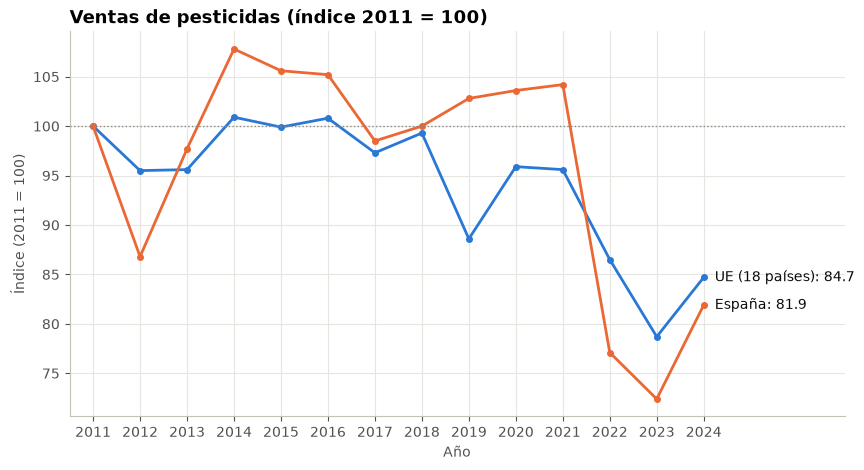

In [5]:
fig, ax = plt.subplots()
ax.plot(ventas["año"], ventas["indice_ue_2011"], color=AZUL_UE, marker="o", markersize=4)
ax.plot(ventas["año"], ventas["indice_espana_2011"], color=NARANJA_ES, marker="o", markersize=4)
ax.axhline(100, color=GRIS, linewidth=1, linestyle=":")

# Etiquetas directas al final de cada línea
ultimo = ventas.iloc[-1]
ax.annotate(f"UE ({int(ultimo['num_paises'])} países): {ultimo['indice_ue_2011']:.1f}", (ultimo["año"], ultimo["indice_ue_2011"]),
            xytext=(8, 0), textcoords="offset points", va="center", color="#0b0b0b")
ax.annotate(f"España: {ultimo['indice_espana_2011']:.1f}", (ultimo["año"], ultimo["indice_espana_2011"]),
            xytext=(8, 0), textcoords="offset points", va="center", color="#0b0b0b")

ax.set_title("Ventas de pesticidas (índice 2011 = 100)")
ax.set_xlabel("Año")
ax.set_ylabel("Índice (2011 = 100)")
ax.set_xticks(ventas["año"])
ax.set_xlim(ventas["año"].min() - 0.5, ventas["año"].max() + 3)
guardar_grafico(fig, "01_ventas_pesticidas_ue_espana")

In [6]:
primero, ultimo = ventas.iloc[0], ventas.iloc[-1]
print(f"UE ({int(ultimo['num_paises'])} países): {primero['millones_kg_ue']} -> {ultimo['millones_kg_ue']} millones de kg "
      f"({ultimo['indice_ue_2011'] - 100:+.1f} % desde 2011)")
print(f"España: {primero['millones_kg_espana']} -> {ultimo['millones_kg_espana']} millones de kg "
      f"({ultimo['indice_espana_2011'] - 100:+.1f} % desde 2011)")
print(f"Mayor caída anual de España: {ventas['var_anual_espana_pct'].min()} % "
      f"en {ventas.loc[ventas['var_anual_espana_pct'].idxmin(), 'año']}")
print(f"Peso de España en el total de los {int(ultimo['num_paises'])} países (2024): {ultimo['cuota_espana_pct']} %")

UE (18 países): 332.37 -> 281.46 millones de kg (-15.3 % desde 2011)
España: 73.11 -> 59.86 millones de kg (-18.1 % desde 2011)
Mayor caída anual de España: -26.0 % en 2022
Peso de España en el total de los 18 países (2024): 21.3 %


### 1.1 Por tipo de pesticida

Para cada grupo se suman los países que tienen **ese grupo** completo los 14 años, por eso el número de países cambia de un grupo a otro.

In [7]:
grupos_ue = ejecutar("02_pesticidas_ue_por_grupo")
grupos_ue[grupos_ue["año"].isin([2011, 2024])]

**Consulta `02_pesticidas_ue_por_grupo`**
```sql
-- Pregunta 1. Ventas en la UE por grupo de pesticida. Para cada grupo se suman
-- los países que tienen ese grupo completo los 14 años (HAVING).
WITH paises_completos_por_grupo AS (
    SELECT codigo_pais, codigo_grupo
    FROM v_pesticidas_por_grupo
    GROUP BY codigo_pais, codigo_grupo
    HAVING COUNT(kg) = 14
),
suma_por_grupo AS (
    SELECT g.año, g.codigo_grupo, g.grupo, COUNT(*) AS num_paises, SUM(g.kg) AS kg
    FROM v_pesticidas_por_grupo      AS g
    JOIN paises_completos_por_grupo  AS c
         ON c.codigo_pais = g.codigo_pais AND c.codigo_grupo = g.codigo_grupo
    GROUP BY g.año, g.codigo_grupo, g.grupo
)
SELECT
    año,
    grupo,
    num_paises,
    ROUND(kg / 1e6, 2)                                                            AS millones_kg,
    ROUND(100.0 * kg / FIRST_VALUE(kg) OVER (PARTITION BY codigo_grupo ORDER BY año), 1) AS indice_2011
FROM suma_por_grupo
ORDER BY codigo_grupo, año;
```

,año,grupo,num_paises,millones_kg,indice_2011
0,2011,Fungicidas y bactericidas,20,146.06,100.0
13,2024,Fungicidas y bactericidas,20,124.73,85.4
14,2011,Herbicidas,23,115.98,100.0
27,2024,Herbicidas,23,107.87,93.0
28,2011,Insecticidas y acaricidas,20,31.85,100.0
41,2024,Insecticidas y acaricidas,20,45.33,142.3
42,2011,Molusquicidas,15,0.79,100.0
55,2024,Molusquicidas,15,1.22,154.4
56,2011,Reguladores del crecimiento,18,9.20,100.0
69,2024,Reguladores del crecimiento,18,7.52,81.7


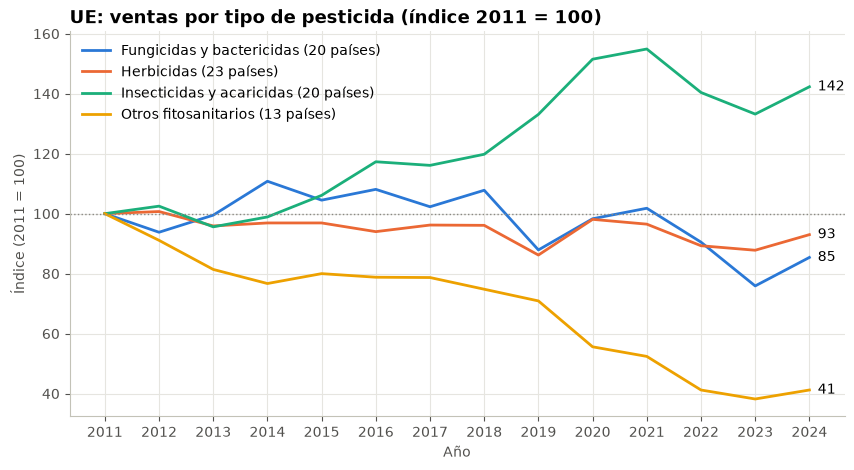

In [8]:
# Los cuatro grupos principales (molusquicidas y reguladores del crecimiento son grupos pequeños)
GRUPOS_PRINCIPALES = ["Fungicidas y bactericidas", "Herbicidas", "Insecticidas y acaricidas", "Otros fitosanitarios"]

indices = grupos_ue.pivot(index="año", columns="grupo", values="indice_2011")[GRUPOS_PRINCIPALES]
paises_por_grupo = grupos_ue.groupby("grupo")["num_paises"].first()

fig, ax = plt.subplots()
for grupo, color in zip(GRUPOS_PRINCIPALES, COLORES_GRUPOS):
    ax.plot(indices.index, indices[grupo], color=color, label=f"{grupo} ({paises_por_grupo[grupo]} países)")
    ax.annotate(f"{indices[grupo].iloc[-1]:.0f}", (indices.index[-1], indices[grupo].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center")
ax.axhline(100, color=GRIS, linewidth=1, linestyle=":")
ax.set_title("UE: ventas por tipo de pesticida (índice 2011 = 100)")
ax.set_xlabel("Año")
ax.set_ylabel("Índice (2011 = 100)")
ax.set_xticks(indices.index)
ax.legend(loc="upper left")
guardar_grafico(fig, "02_ue_por_tipo")

In [9]:
grupos_es = ejecutar("03_pesticidas_espana_por_grupo")
grupos_es[grupos_es["año"] == 2024]

**Consulta `03_pesticidas_espana_por_grupo`**
```sql
-- Pregunta 1. España: ventas por grupo y peso de cada grupo en el total del año.
-- CASE marca los datos confidenciales.
SELECT
    g.año,
    g.grupo,
    ROUND(g.kg / 1e6, 2)                    AS millones_kg,
    ROUND(100.0 * g.kg / t.kg, 1)           AS pct_del_total,
    CASE WHEN g.kg IS NULL THEN 'confidencial' ELSE 'publicado' END AS estado_dato
FROM v_pesticidas_por_grupo AS g
JOIN fact_ventas_pesticidas AS t
     ON t.codigo_pais = g.codigo_pais AND t.año = g.año AND t.codigo_pesticida = 'TOTAL'
WHERE g.codigo_pais = 'ES'
ORDER BY g.año, g.codigo_grupo;
```

,año,grupo,millones_kg,pct_del_total,estado_dato
78,2024,Fungicidas y bactericidas,27.50,45.9,publicado
79,2024,Herbicidas,17.81,29.7,publicado
80,2024,Insecticidas y acaricidas,10.96,18.3,publicado
81,2024,Molusquicidas,NaN,NaN,confidencial
82,2024,Reguladores del crecimiento,NaN,NaN,confidencial
83,2024,Otros fitosanitarios,3.41,5.7,publicado


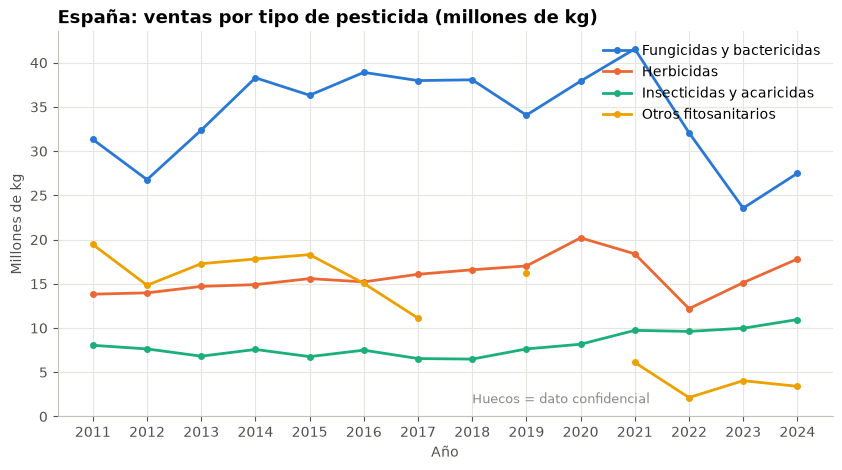

In [10]:
kg_es = grupos_es.pivot(index="año", columns="grupo", values="millones_kg")[GRUPOS_PRINCIPALES]

fig, ax = plt.subplots()
for grupo, color in zip(GRUPOS_PRINCIPALES, COLORES_GRUPOS):
    ax.plot(kg_es.index, kg_es[grupo], color=color, marker="o", markersize=4, label=grupo)
ax.set_title("España: ventas por tipo de pesticida (millones de kg)")
ax.set_xlabel("Año")
ax.set_ylabel("Millones de kg")
ax.set_xticks(kg_es.index)
ax.set_ylim(0)
ax.legend(loc="upper right")
ax.text(2018, 1.5, "Huecos = dato confidencial", color=GRIS, fontsize=9)
guardar_grafico(fig, "03_espana_por_tipo")

In [11]:
cambio_grupos_es = ejecutar("04_cambio_por_grupo_espana")
cambio_grupos_es

**Consulta `04_cambio_por_grupo_espana`**
```sql
-- Pregunta 1. España: cambio de cada grupo entre 2011, la media 2015-2017
-- (referencia de la estrategia) y 2024. Se "pivotan" los años con CASE.
-- Molusquicidas y reguladores del crecimiento quedan fuera: son confidenciales.
WITH tres_periodos AS (
    SELECT
        codigo_grupo,
        grupo,
        SUM(CASE WHEN año = 2011 THEN kg END)                 AS kg_2011,
        AVG(CASE WHEN año BETWEEN 2015 AND 2017 THEN kg END)  AS kg_2015_2017,
        SUM(CASE WHEN año = 2024 THEN kg END)                 AS kg_2024
    FROM v_pesticidas_por_grupo
    WHERE codigo_pais = 'ES'
    GROUP BY codigo_grupo, grupo
)
SELECT
    grupo,
    ROUND(kg_2011 / 1e6, 2)                                   AS millones_kg_2011,
    ROUND(kg_2015_2017 / 1e6, 2)                              AS millones_kg_2015_2017,
    ROUND(kg_2024 / 1e6, 2)                                   AS millones_kg_2024,
    ROUND(100.0 * (kg_2024 - kg_2011) / kg_2011, 1)           AS cambio_desde_2011_pct,
    ROUND(100.0 * (kg_2024 - kg_2015_2017) / kg_2015_2017, 1) AS cambio_desde_2015_2017_pct
FROM tres_periodos
WHERE kg_2011 IS NOT NULL AND kg_2024 IS NOT NULL
ORDER BY kg_2024 DESC;
```

,grupo,millones_kg_2011,millones_kg_2015_2017,millones_kg_2024,cambio_desde_2011_pct,cambio_desde_2015_2017_pct
0,Fungicidas y bactericidas,31.33,37.74,27.50,-12.2,-27.1
1,Herbicidas,13.83,15.63,17.81,28.7,13.9
2,Insecticidas y acaricidas,8.05,6.94,10.96,36.2,57.9
3,Otros fitosanitarios,19.45,14.82,3.41,-82.5,-77.0


**Respuesta a la pregunta 1**

- En el conjunto de los 18 países con serie completa, las ventas apenas se movieron entre 2011 y 2021 y **bajan a partir de 2022**.
  En 2024 están un **15,3 % por debajo de 2011** (de 332,37 a 281,46 millones de kg).
- España vende **59,86 millones de kg** en 2024 (21,3 % del total de esos 18 países). Mantuvo sus ventas estables hasta 2021,
  cayó un **26 % en 2022** y en 2024 está un **18,1 % por debajo de 2011**.
- Por tipo, los **fungicidas** son el grupo más vendido (en España, el 45,9 % de los kg en 2024). Los **insecticidas suben** tanto en la UE
  (índice 142) como en España (+36,2 % desde 2011), y los **"otros fitosanitarios"** (aceites, esterilizantes del suelo...) son los que más caen
  (−82,5 % en España).

## 2. Fertilizantes minerales: nitrógeno y fósforo

El agregado oficial UE-27 solo llega a 2019, así que la UE se calcula como **suma de los 25 países con serie completa**
(faltan Chipre y Malta, que tienen años sin dato). La columna `millones_t_ue27_oficial` permite comprobar que la suma
de esos 25 países se parece mucho al dato oficial hasta 2019. Los datos de España de 2022-2024 son **provisionales** (`p`).

In [12]:
fertilizantes = ejecutar("05_fertilizantes_ue_espana")
fertilizantes

**Consulta `05_fertilizantes_ue_espana`**
```sql
-- Pregunta 2. Fertilizantes minerales (N y P) en la UE y en España.
-- UE = suma de los países con serie completa 2011-2024; se compara con el
-- agregado oficial UE-27, que Eurostat solo publica hasta 2019.
WITH paises_completos AS (
    SELECT codigo_pais, codigo_nutriente
    FROM fact_fertilizantes
    WHERE codigo_pais <> 'EU27_2020'
    GROUP BY codigo_pais, codigo_nutriente
    HAVING COUNT(toneladas) = 14
),
suma_ue AS (
    SELECT
        f.año,
        f.codigo_nutriente,
        COUNT(*)          AS num_paises,
        SUM(f.toneladas)  AS toneladas_ue,
        SUM(s.sau_ha)     AS sau_ha_ue
    FROM fact_fertilizantes AS f
    JOIN paises_completos   AS c ON c.codigo_pais = f.codigo_pais AND c.codigo_nutriente = f.codigo_nutriente
    JOIN fact_sau           AS s ON s.codigo_pais = f.codigo_pais AND s.año = f.año
    GROUP BY f.año, f.codigo_nutriente
)
SELECT
    u.año,
    n.nutriente,
    u.num_paises,
    ROUND(u.toneladas_ue / 1e6, 3)                                                   AS millones_t_ue,
    ROUND(oficial.toneladas / 1e6, 3)                                                AS millones_t_ue27_oficial,
    ROUND(u.toneladas_ue * 1000 / u.sau_ha_ue, 1)                                    AS kg_ha_ue,
    ROUND(100.0 * u.toneladas_ue
          / FIRST_VALUE(u.toneladas_ue) OVER (PARTITION BY u.codigo_nutriente ORDER BY u.año), 1) AS indice_ue_2011,
    ROUND(es.toneladas / 1e3, 1)                                                     AS miles_t_espana,
    ROUND(es.kg_ha, 1)                                                               AS kg_ha_espana,
    ROUND(100.0 * es.toneladas
          / FIRST_VALUE(es.toneladas) OVER (PARTITION BY u.codigo_nutriente ORDER BY u.año), 1)   AS indice_espana_2011,
    es.nota                                                                          AS nota_espana
FROM suma_ue                    AS u
JOIN dim_nutriente              AS n  ON n.codigo_nutriente = u.codigo_nutriente
LEFT JOIN fact_fertilizantes    AS oficial
     ON oficial.año = u.año AND oficial.codigo_nutriente = u.codigo_nutriente AND oficial.codigo_pais = 'EU27_2020'
LEFT JOIN v_fertilizantes_kg_ha AS es
     ON es.año = u.año AND es.nutriente = n.nutriente AND es.codigo_pais = 'ES'
ORDER BY n.nutriente DESC, u.año;
```

,año,nutriente,num_paises,millones_t_ue,millones_t_ue27_oficial,kg_ha_ue,indice_ue_2011,miles_t_espana,kg_ha_espana,indice_espana_2011,nota_espana
0,2011,Nitrógeno,25,9.727,9.575,59.9,100.0,846.7,35.4,100.0,NaN
1,2012,Nitrógeno,25,9.522,9.535,59.2,97.9,843.4,35.9,99.6,NaN
2,2013,Nitrógeno,25,9.824,9.826,61.1,101.0,961.5,40.9,113.6,NaN
3,2014,Nitrógeno,25,10.045,10.119,62.4,103.3,1101.9,46.7,130.1,NaN
4,2015,Nitrógeno,25,10.333,10.237,64.0,106.2,1068.1,44.7,126.1,NaN
5,2016,Nitrógeno,25,10.273,10.366,63.8,105.6,982.2,41.2,116.0,NaN
6,2017,Nitrógeno,25,10.517,10.478,65.3,108.1,1072.1,45.0,126.6,NaN
7,2018,Nitrógeno,25,10.350,10.194,64.1,106.4,1033.5,42.7,122.1,NaN
8,2019,Nitrógeno,25,9.850,9.842,60.6,101.3,1011.3,41.5,119.4,NaN
9,2020,Nitrógeno,25,9.945,NaN,61.5,102.2,1059.3,43.4,125.1,NaN


In [13]:
# Comprobación: diferencia entre la suma de 25 países y el total oficial UE-27 (2011-2019)
comprobacion = fertilizantes.dropna(subset=["millones_t_ue27_oficial"]).copy()
comprobacion["diferencia_pct"] = 100 * (comprobacion["millones_t_ue"] / comprobacion["millones_t_ue27_oficial"] - 1)
print("Diferencia máxima con el dato oficial:", round(comprobacion["diferencia_pct"].abs().max(), 1), "%")

Diferencia máxima con el dato oficial: 2.4 %


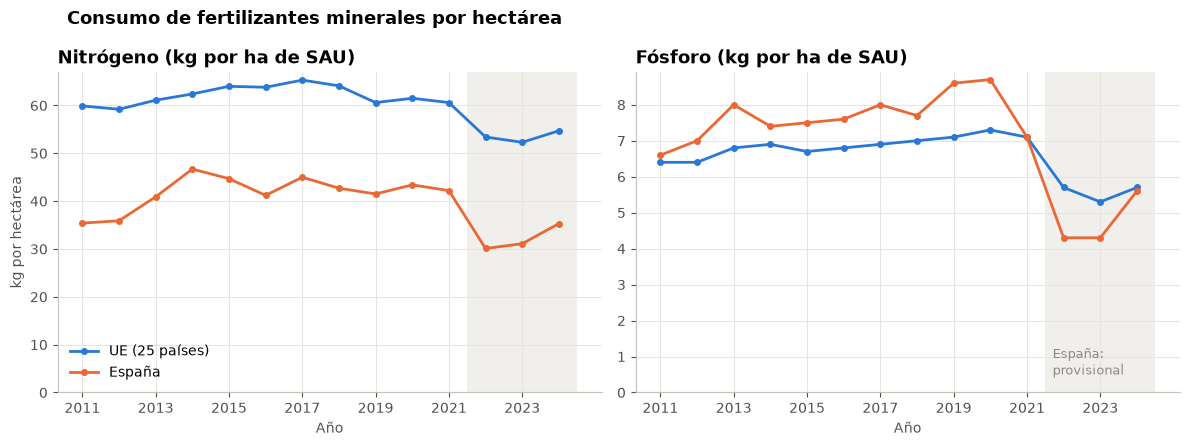

In [14]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, nutriente in zip(ejes, ["Nitrógeno", "Fósforo"]):
    datos = fertilizantes[fertilizantes["nutriente"] == nutriente]
    ax.plot(datos["año"], datos["kg_ha_ue"], color=AZUL_UE, marker="o", markersize=4, label="UE (25 países)")
    ax.plot(datos["año"], datos["kg_ha_espana"], color=NARANJA_ES, marker="o", markersize=4, label="España")
    ax.axvspan(2021.5, 2024.5, color="#e6e5e0", alpha=0.6, linewidth=0)
    ax.set_title(f"{nutriente} (kg por ha de SAU)")
    ax.set_xlabel("Año")
    ax.set_ylim(0)
    ax.set_xticks(range(2011, 2025, 2))
ejes[0].set_ylabel("kg por hectárea")
ejes[0].legend(loc="lower left")
ejes[1].text(2021.7, 0.5, "España:\nprovisional", color=GRIS, fontsize=9)
fig.suptitle("Consumo de fertilizantes minerales por hectárea", x=0.06, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
guardar_grafico(fig, "04_fertilizantes")

In [15]:
def cambio(nutriente, columna, año_a, año_b):
    datos = fertilizantes[fertilizantes["nutriente"] == nutriente].set_index("año")[columna]
    return round(100 * (datos[año_b] / datos[año_a] - 1), 1)

for nutriente in ["Nitrógeno", "Fósforo"]:
    print(f"{nutriente}: UE {cambio(nutriente, 'millones_t_ue', 2011, 2024):+} % (2011-2024), "
          f"{cambio(nutriente, 'millones_t_ue', 2021, 2024):+} % (2021-2024) | "
          f"España {cambio(nutriente, 'miles_t_espana', 2011, 2024):+} % (2011-2024), "
          f"{cambio(nutriente, 'miles_t_espana', 2021, 2024):+} % (2021-2024)")

Nitrógeno: UE -10.0 % (2011-2024), -10.3 % (2021-2024) | España +3.0 % (2011-2024), -15.3 % (2021-2024)
Fósforo: UE -12.8 % (2011-2024), -21.0 % (2021-2024) | España -12.6 % (2011-2024), -20.1 % (2021-2024)


**Respuesta a la pregunta 2**

- El consumo de **nitrógeno** en la UE sube hasta 2017 y cae con fuerza en **2022**, año en que se dispararon
  los precios de los fertilizantes. En 2024 la UE usa un **10 % menos de nitrógeno** y un **12,8 % menos de fósforo** que en 2011.
- España usa **menos fertilizante por hectárea** que la media de la UE (35,3 kg de N/ha frente a 54,7 en 2024), porque tiene mucho cultivo de secano y pastos.
  Tras la caída de 2022 vuelve a subir: en 2024 ya consume un **3 % más de nitrógeno que en 2011** (dato provisional).

## 3. Exceso de nitrógeno: balance de nutrientes

El **balance bruto de nitrógeno** es la diferencia entre lo que entra en el suelo (fertilizantes, estiércol, fijación biológica...)
y lo que se llevan las cosechas. Un balance alto indica **nitrógeno sobrante**, que puede acabar en ríos y acuíferos (nitratos).

Varios países (Bélgica, Chipre, Dinamarca, Grecia, Luxemburgo, Malta y Estonia) no publican datos desde 2015 o antes,
por eso se hacen **dos rankings** separados.

In [16]:
nitrogeno = ejecutar("06_ranking_exceso_nitrogeno")
nitrogeno

**Consulta `06_ranking_exceso_nitrogeno`**
```sql
-- Pregunta 3. Ranking de exceso de nitrógeno (kg N por ha) con el último año
-- disponible de cada país. Como varios países solo tienen datos hasta 2015,
-- se hacen dos rankings separados (PARTITION BY) para no mezclar épocas.
WITH ultimo_año AS (
    SELECT codigo_pais, MAX(año) AS año
    FROM fact_balance_nutrientes
    WHERE codigo_nutriente = 'N' AND balance_kg_ha IS NOT NULL AND codigo_pais <> 'EU27_2020'
    GROUP BY codigo_pais
),
ultimo_dato AS (
    SELECT
        b.codigo_pais,
        b.año,
        b.balance_kg_ha,
        b.nota,
        CASE WHEN b.año >= 2020 THEN 'reciente (2020-2023)' ELSE 'antiguo (2012-2015)' END AS periodo_dato
    FROM fact_balance_nutrientes AS b
    JOIN ultimo_año              AS u ON u.codigo_pais = b.codigo_pais AND u.año = b.año
    WHERE b.codigo_nutriente = 'N'
)
SELECT
    d.periodo_dato,
    RANK() OVER (PARTITION BY d.periodo_dato ORDER BY d.balance_kg_ha DESC) AS ranking,
    p.pais,
    d.año                                        AS año_dato,
    ROUND(d.balance_kg_ha, 1)                    AS exceso_n_kg_ha,
    -- diferencia con la media de los países con dato reciente (subconsulta)
    ROUND(d.balance_kg_ha - (
        SELECT AVG(balance_kg_ha) FROM ultimo_dato WHERE año >= 2020
    ), 1)                                        AS diferencia_media_reciente,
    CASE WHEN d.nota LIKE '%e%' THEN 'estimado' ELSE '' END AS aviso
FROM ultimo_dato AS d
JOIN dim_pais    AS p ON p.codigo_pais = d.codigo_pais
ORDER BY d.periodo_dato DESC, ranking;
```

,periodo_dato,ranking,pais,año_dato,exceso_n_kg_ha,diferencia_media_reciente,aviso
0,reciente (2020-2023),1,Países Bajos,2023,136.8,95.9,
1,reciente (2020-2023),2,Italia,2023,57.8,16.9,
2,reciente (2020-2023),3,Finlandia,2023,53.4,12.5,
3,reciente (2020-2023),4,Eslovenia,2021,50.3,9.4,
4,reciente (2020-2023),5,Croacia,2023,48.6,7.7,
5,reciente (2020-2023),6,Hungría,2023,45.0,4.1,
6,reciente (2020-2023),7,Bulgaria,2023,44.0,3.1,
7,reciente (2020-2023),8,Chequia,2023,43.6,2.7,
8,reciente (2020-2023),9,Suecia,2023,40.6,-0.3,
9,reciente (2020-2023),10,España,2023,37.9,-3.0,


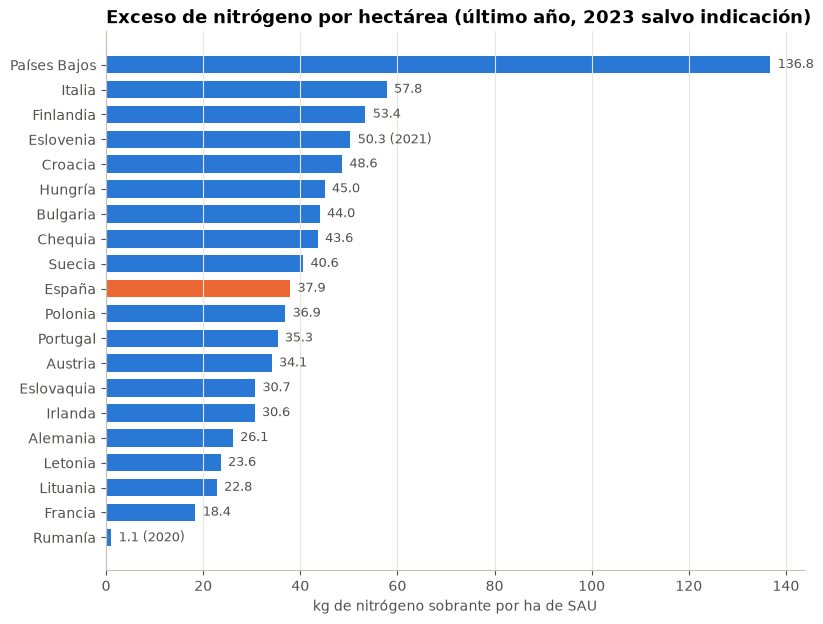

In [17]:
recientes = nitrogeno[nitrogeno["periodo_dato"].str.startswith("reciente")].sort_values("exceso_n_kg_ha")
colores = [NARANJA_ES if p == "España" else AZUL_UE for p in recientes["pais"]]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(recientes["pais"], recientes["exceso_n_kg_ha"], color=colores, height=0.7)
for posicion, (valor, año) in enumerate(zip(recientes["exceso_n_kg_ha"], recientes["año_dato"])):
    etiqueta = f"{valor:.1f}" if año == 2023 else f"{valor:.1f} ({año})"
    ax.text(valor + 1.5, posicion, etiqueta, va="center", fontsize=9, color="#52514e")
ax.set_title("Exceso de nitrógeno por hectárea (último año, 2023 salvo indicación)")
ax.set_xlabel("kg de nitrógeno sobrante por ha de SAU")
ax.grid(axis="y", visible=False)
guardar_grafico(fig, "05_ranking_nitrogeno")

**Respuesta a la pregunta 3**

- Entre los países con dato reciente, **Países Bajos** tiene con diferencia el mayor exceso: **136,8 kg de N por hectárea** en 2023,
  más del doble que el segundo (Italia, 57,8). Es el efecto de una ganadería muy intensiva en poca superficie.
- Con datos de 2015 (los últimos que publican), **Chipre, Malta, Bélgica y Luxemburgo** también superaban los 125 kg/ha.
- **España** está en la zona media-baja (37,9 kg/ha, puesto 10 de 20 con dato reciente), por debajo de la media de esos países.

## 4. ¿Más agricultura ecológica, menos pesticidas?

Para cada país se calcula la **media 2020-2024** del % de superficie ecológica y de los **kg de pesticida vendidos por hectárea** de SAU
(solo países con al menos 3 años con ambos datos). Se añade el peso de los **fungicidas inorgánicos** (cobre y azufre), que
están permitidos en agricultura ecológica y pesan mucho en kilos.

In [18]:
eco = ejecutar("07_ecologico_vs_pesticidas")
eco

**Consulta `07_ecologico_vs_pesticidas`**
```sql
-- Pregunta 4. Por país: media 2020-2024 del % de superficie ecológica y de los
-- kg de pesticida por hectárea. Solo países con al menos 3 años de ambos datos.
-- Se añade el peso de los fungicidas inorgánicos (cobre, azufre), que también
-- se usan en agricultura ecológica.
WITH datos_pais_año AS (
    SELECT
        v.codigo_pais,
        v.pais,
        v.año,
        v.kg_ha,
        e.pct_sau_ecologica,
        100.0 * f01.kg / v.kg_total AS pct_fungicidas_inorganicos
    FROM v_pesticidas_kg_ha  AS v
    JOIN fact_pct_ecologica  AS e ON e.codigo_pais = v.codigo_pais AND e.año = v.año
    LEFT JOIN fact_ventas_pesticidas AS f01
         ON f01.codigo_pais = v.codigo_pais AND f01.año = v.año AND f01.codigo_pesticida = 'F01'
    WHERE v.año BETWEEN 2020 AND 2024
      AND v.kg_ha IS NOT NULL
      AND e.pct_sau_ecologica IS NOT NULL
)
SELECT
    codigo_pais,
    pais,
    COUNT(*)                                  AS años_con_dato,
    ROUND(AVG(pct_sau_ecologica), 1)          AS pct_ecologica,
    ROUND(AVG(kg_ha), 2)                      AS kg_pesticida_ha,
    ROUND(AVG(pct_fungicidas_inorganicos), 1) AS pct_fungicidas_inorganicos
FROM datos_pais_año
GROUP BY codigo_pais, pais
HAVING COUNT(*) >= 3
ORDER BY pct_ecologica DESC;
```

,codigo_pais,pais,años_con_dato,pct_ecologica,kg_pesticida_ha,pct_fungicidas_inorganicos
0,SE,Suecia,5,19.1,0.71,NaN
1,PT,Portugal,5,18.1,2.30,44.8
2,IT,Italia,5,17.8,3.54,42.9
3,CZ,Chequia,5,15.8,1.30,7.4
4,LV,Letonia,5,15.3,0.93,0.1
5,FI,Finlandia,5,14.1,1.68,0.1
6,SK,Eslovaquia,4,14.1,1.08,6.6
7,DK,Dinamarca,5,11.4,1.23,0.1
8,ES,España,5,11.1,2.61,44.2
9,SI,Eslovenia,5,11.1,1.71,45.0


In [19]:
correlacion = eco["pct_ecologica"].corr(eco["kg_pesticida_ha"])
sin_islas = eco[~eco["codigo_pais"].isin(["MT", "CY"])]
correlacion_sin_islas = sin_islas["pct_ecologica"].corr(sin_islas["kg_pesticida_ha"])
correlacion_inorganicos = eco["pct_ecologica"].corr(eco["pct_fungicidas_inorganicos"])

print(f"Países analizados: {len(eco)}")
print(f"Correlación % ecológico vs kg/ha (todos):              {correlacion:.2f}")
print(f"Correlación % ecológico vs kg/ha (sin Malta y Chipre): {correlacion_sin_islas:.2f}")
print(f"Correlación % ecológico vs % fungicidas inorgánicos:   {correlacion_inorganicos:.2f}")

Países analizados: 24
Correlación % ecológico vs kg/ha (todos):              -0.31
Correlación % ecológico vs kg/ha (sin Malta y Chipre): 0.03
Correlación % ecológico vs % fungicidas inorgánicos:   0.04


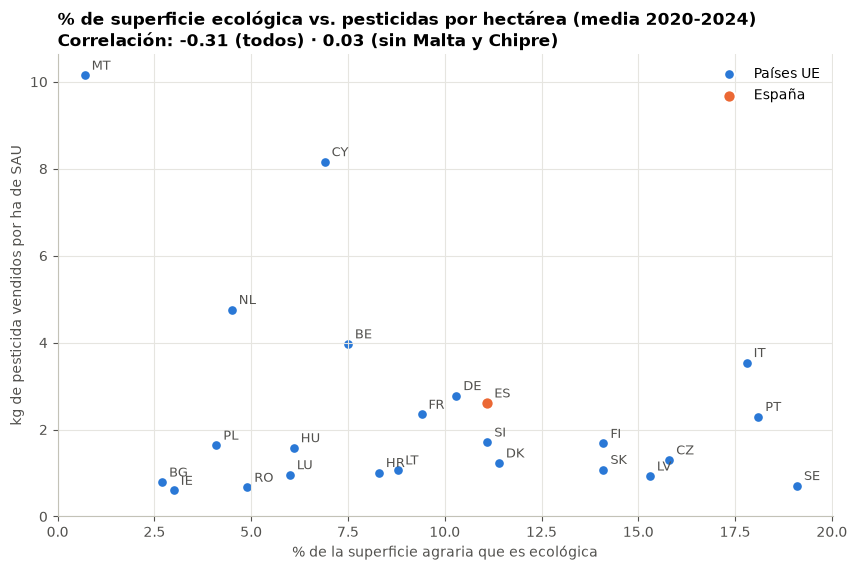

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
otros = eco[eco["codigo_pais"] != "ES"]
espana = eco[eco["codigo_pais"] == "ES"]
ax.scatter(otros["pct_ecologica"], otros["kg_pesticida_ha"], s=60, color=AZUL_UE,
           edgecolor="white", linewidth=1.5, label="Países UE")
ax.scatter(espana["pct_ecologica"], espana["kg_pesticida_ha"], s=80, color=NARANJA_ES,
           edgecolor="white", linewidth=1.5, label="España")
for _, fila in eco.iterrows():
    ax.annotate(fila["codigo_pais"], (fila["pct_ecologica"], fila["kg_pesticida_ha"]),
                xytext=(5, 4), textcoords="offset points", fontsize=9, color="#52514e")
ax.set_title(f"% de superficie ecológica vs. pesticidas por hectárea (media 2020-2024)\n"
             f"Correlación: {correlacion:.2f} (todos) · {correlacion_sin_islas:.2f} (sin Malta y Chipre)",
             fontsize=12)
ax.set_xlabel("% de la superficie agraria que es ecológica")
ax.set_ylabel("kg de pesticida vendidos por ha de SAU")
ax.set_xlim(0)
ax.set_ylim(0)
ax.legend(loc="upper right")
guardar_grafico(fig, "06_ecologico_vs_pesticidas")

**Respuesta a la pregunta 4**

- La relación entre países es **débil**: la correlación es negativa pero pequeña, y depende mucho de **Malta y Chipre**,
  dos islas con poca superficie agraria y muchos kg por hectárea. Sin ellas, la relación prácticamente desaparece.
- Los países mediterráneos (Portugal, Italia, España, Eslovenia) combinan **mucho ecológico y muchos kg por hectárea**.
  Parte de la explicación está en los **fungicidas inorgánicos** (azufre y cobre): son más del 40 % de los kg que venden,
  se aplican en dosis altas en viñedo, frutales y olivar, y **también se usan en agricultura ecológica**.
- ⚠️ **Correlación no es causalidad.** Esta comparación no demuestra que el ecológico reduzca (o no) el uso de pesticidas:
  los países se diferencian en clima, tipo de cultivos, tamaño de las explotaciones y forma de registrar las ventas.
  Además, los kg vendidos no miden la peligrosidad de cada sustancia. Para saberlo habría que comparar explotaciones
  parecidas, no medias de países.

## 5. ¿Va la UE camino del −50 % de pesticidas en 2030?

El objetivo de la estrategia se mide respecto a la **media 2015-2017**. Hay dos formas de medirlo:

1. **Kilos vendidos** (`aei_fm_salpest09`): todos los kg cuentan igual.
2. **Indicador oficial de uso y riesgo** (`sdg_02_53`): pondera cada sustancia por su peligrosidad. Es el que usa la Comisión Europea
   para seguir el objetivo. Valor 100 = media 2015-2017; el objetivo es llegar a **50** en 2030.

La proyección es una **extrapolación aritmética**, igual que en el proyecto 1: se calcula la tasa anual media entre el periodo
de referencia (centrado en 2016) y el último año, y se supone que se mantiene hasta 2030. **No es un modelo predictivo**,
solo responde a "¿qué pasaría si todo sigue igual?".

In [21]:
base_ventas = ejecutar("08_base_proyeccion_ventas")
base_ventas

**Consulta `08_base_proyeccion_ventas`**
```sql
-- Pregunta 5. Datos de partida para la proyección a 2030 de las ventas en kg:
-- media 2015-2017 (periodo de referencia de la estrategia) y último año.
WITH paises_serie_completa AS (
    SELECT codigo_pais
    FROM fact_ventas_pesticidas
    WHERE codigo_pesticida = 'TOTAL'
    GROUP BY codigo_pais
    HAVING COUNT(kg) = 14
),
series AS (
    SELECT 'UE (países con serie completa)' AS ambito, v.año, SUM(v.kg) AS kg
    FROM fact_ventas_pesticidas AS v
    JOIN paises_serie_completa  AS c ON c.codigo_pais = v.codigo_pais
    WHERE v.codigo_pesticida = 'TOTAL'
    GROUP BY v.año
    UNION ALL
    SELECT 'España', año, kg
    FROM fact_ventas_pesticidas
    WHERE codigo_pesticida = 'TOTAL' AND codigo_pais = 'ES'
)
SELECT
    ambito,
    AVG(CASE WHEN año BETWEEN 2015 AND 2017 THEN kg END)          AS kg_media_2015_2017,
    MAX(año)                                                       AS ultimo_año,
    SUM(CASE WHEN año = (SELECT MAX(año) FROM series) THEN kg END) AS kg_ultimo_año
FROM series
GROUP BY ambito
ORDER BY ambito DESC;
```

,ambito,kg_media_2015_2017,ultimo_año,kg_ultimo_año
0,UE (países con serie completa),330165070.0,2024,281457214.0
1,España,75381573.0,2024,59857799.0


In [22]:
riesgo = ejecutar("09_indicador_riesgo_ue_espana")
riesgo[riesgo["año"] >= 2019]

**Consulta `09_indicador_riesgo_ue_espana`**
```sql
-- Pregunta 5. Indicador oficial "uso y riesgo de pesticidas químicos"
-- (media 2015-2017 = 100; el objetivo 2030 es 50) para la UE-27 y España.
SELECT
    r.año,
    p.pais,
    r.indice_2015_2017,
    r.indice_2015_2017 - LAG(r.indice_2015_2017) OVER (PARTITION BY r.codigo_pais ORDER BY r.año) AS cambio_anual
FROM fact_riesgo_pesticidas AS r
JOIN dim_pais               AS p ON p.codigo_pais = r.codigo_pais
WHERE r.codigo_pais IN ('EU27_2020', 'ES')
ORDER BY p.pais DESC, r.año;
```

,año,pais,indice_2015_2017,cambio_anual
8,2019,UE-27,86.0,-10.0
9,2020,UE-27,77.0,-9.0
10,2021,UE-27,66.0,-11.0
11,2022,UE-27,48.0,-18.0
12,2023,UE-27,42.0,-6.0
21,2019,España,97.0,12.0
22,2020,España,91.0,-6.0
23,2021,España,74.0,-17.0
24,2022,España,36.0,-38.0
25,2023,España,35.0,-1.0


In [23]:
AÑO_BASE = 2016       # centro del periodo de referencia 2015-2017
AÑO_OBJETIVO = 2030


def proyectar(ambito, medida, valor_base, valor_ultimo, año_ultimo):
    """Proyección aritmética: mantiene hasta 2030 la tasa anual media observada."""
    años_transcurridos = año_ultimo - AÑO_BASE
    años_restantes = AÑO_OBJETIVO - año_ultimo
    tasa_anual = (valor_ultimo / valor_base) ** (1 / años_transcurridos) - 1
    valor_2030 = valor_ultimo * (1 + tasa_anual) ** años_restantes
    tasa_necesaria = (0.5 * valor_base / valor_ultimo) ** (1 / años_restantes) - 1
    # Si ya está por debajo del objetivo, no hace falta ninguna reducción adicional
    if valor_ultimo <= 0.5 * valor_base:
        texto_necesaria = "ya cumplido"
    else:
        texto_necesaria = round(100 * tasa_necesaria, 1)
    return {
        "ámbito": ambito,
        "medida": medida,
        "último año": año_ultimo,
        "cambio hasta el último año (%)": round(100 * (valor_ultimo / valor_base - 1), 1),
        "tasa anual media (%)": round(100 * tasa_anual, 1),
        "cambio proyectado en 2030 (%)": round(100 * (valor_2030 / valor_base - 1), 1),
        "tasa anual necesaria para −50 % (%)": texto_necesaria,
        "¿llega al −50 %?": "Sí" if valor_2030 <= 0.5 * valor_base else "No",
    }


filas = []
for _, fila in base_ventas.iterrows():
    nombre = "UE (18 países)" if fila["ambito"].startswith("UE") else "España"
    filas.append(proyectar(nombre, "kg vendidos", fila["kg_media_2015_2017"], fila["kg_ultimo_año"], fila["ultimo_año"]))

for pais, nombre in [("UE-27", "UE-27"), ("España", "España")]:
    serie = riesgo[(riesgo["pais"] == pais) & riesgo["indice_2015_2017"].notna()]
    ultimo = serie.iloc[-1]
    filas.append(proyectar(nombre, "indicador de uso y riesgo", 100, ultimo["indice_2015_2017"], ultimo["año"]))

proyeccion = pd.DataFrame(filas)
proyeccion.to_csv(CARPETA_OUTPUT / "proyeccion_2030.csv", index=False, encoding="utf-8")
proyeccion

,ámbito,medida,último año,cambio hasta el último año (%),tasa anual media (%),cambio proyectado en 2030 (%),tasa anual necesaria para −50 % (%),¿llega al −50 %?
0,UE (18 países),kg vendidos,2024,-14.8,-2.0,-24.4,-8.5,No
1,España,kg vendidos,2024,-20.6,-2.8,-33.2,-7.4,No
2,UE-27,indicador de uso y riesgo,2023,-58.0,-11.7,-82.4,ya cumplido,Sí
3,España,indicador de uso y riesgo,2023,-65.0,-13.9,-87.8,ya cumplido,Sí


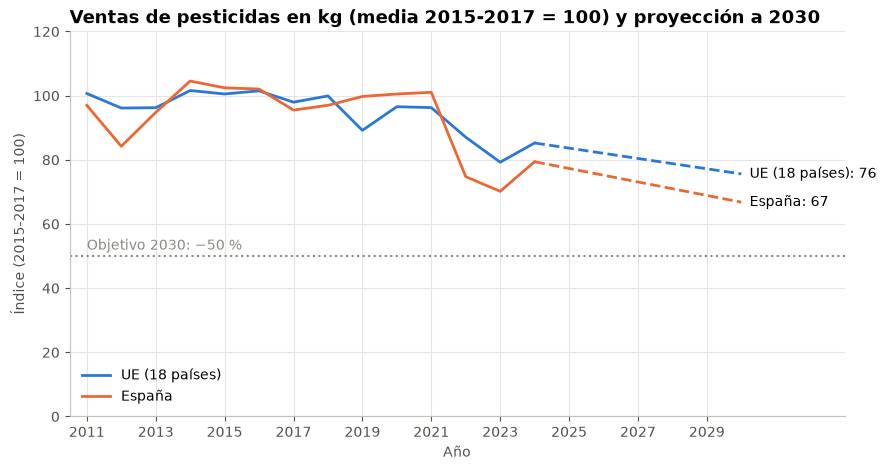

In [24]:
# Gráfico: kilos vendidos en índice (media 2015-2017 = 100) con la proyección a 2030
fig, ax = plt.subplots()
series_kg = {
    "UE (18 países)": (ventas["millones_kg_ue"], base_ventas.iloc[0]["kg_media_2015_2017"] / 1e6, AZUL_UE),
    "España": (ventas["millones_kg_espana"], base_ventas.iloc[1]["kg_media_2015_2017"] / 1e6, NARANJA_ES),
}
for nombre, (kg, base, color) in series_kg.items():
    indice = 100 * kg / base
    ax.plot(ventas["año"], indice, color=color, label=nombre)
    datos_proy = proyeccion[(proyeccion["ámbito"] == nombre) & (proyeccion["medida"] == "kg vendidos")].iloc[0]
    valor_2030 = 100 + datos_proy["cambio proyectado en 2030 (%)"]
    ax.plot([2024, 2030], [indice.iloc[-1], valor_2030], color=color, linestyle="--")
    ax.annotate(f"{nombre}: {valor_2030:.0f}", (2030, valor_2030), xytext=(6, 0),
                textcoords="offset points", va="center")
ax.axhline(50, color=GRIS, linestyle=":", linewidth=1.5)
ax.text(2011, 52, "Objetivo 2030: −50 %", color=GRIS)
ax.set_title("Ventas de pesticidas en kg (media 2015-2017 = 100) y proyección a 2030")
ax.set_xlabel("Año")
ax.set_ylabel("Índice (2015-2017 = 100)")
ax.set_ylim(0, 120)
ax.set_xlim(2010.5, 2033)
ax.set_xticks(range(2011, 2031, 2))
ax.legend(loc="lower left")
guardar_grafico(fig, "07_proyeccion_kg_2030")

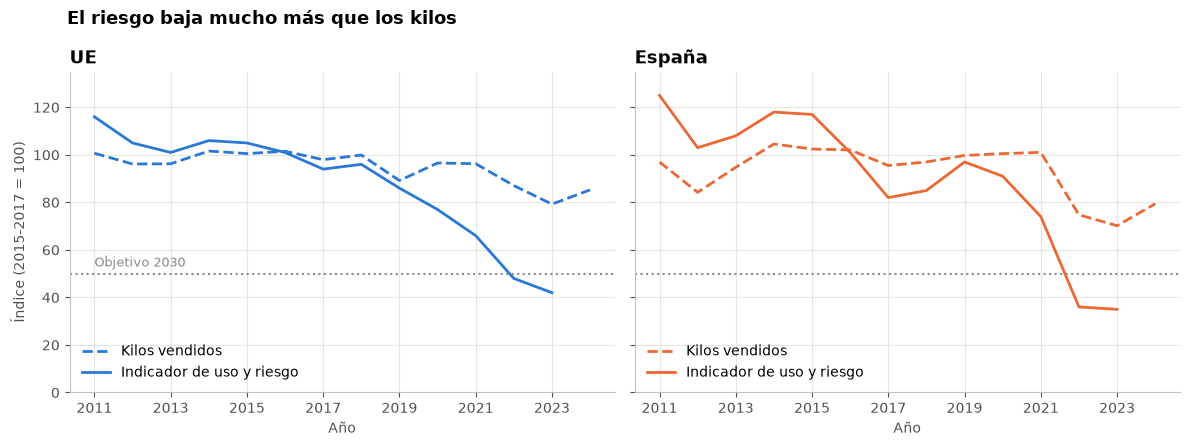

In [25]:
# Gráfico: kilos vs. indicador de riesgo, misma base (2015-2017 = 100)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
paneles = [("UE", "UE-27", AZUL_UE, "millones_kg_ue", 0), ("España", "España", NARANJA_ES, "millones_kg_espana", 1)]
for ax, (titulo, pais, color, columna_kg, fila_base) in zip(ejes, paneles):
    indice_kg = 100 * ventas[columna_kg] / (base_ventas.iloc[fila_base]["kg_media_2015_2017"] / 1e6)
    serie_riesgo = riesgo[riesgo["pais"] == pais]
    ax.plot(ventas["año"], indice_kg, color=color, linestyle="--", label="Kilos vendidos")
    ax.plot(serie_riesgo["año"], serie_riesgo["indice_2015_2017"], color=color, label="Indicador de uso y riesgo")
    ax.axhline(50, color=GRIS, linestyle=":", linewidth=1.5)
    ax.set_title(titulo)
    ax.set_xlabel("Año")
    ax.set_xticks(range(2011, 2025, 2))
    ax.set_ylim(0, 135)
    ax.legend(loc="lower left")
ejes[0].set_ylabel("Índice (2015-2017 = 100)")
ejes[0].text(2011, 53, "Objetivo 2030", color=GRIS, fontsize=9)
fig.suptitle("El riesgo baja mucho más que los kilos", x=0.06, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
guardar_grafico(fig, "08_riesgo_vs_kilos")

### 5.1 ¿Por qué el riesgo baja más que los kilos?

El indicador oficial da a cada grupo de sustancias un **peso según su peligrosidad**: las sustancias **no aprobadas** (prohibidas)
pesan 64 veces más que las de bajo riesgo. Cuando una sustancia se prohíbe, sus ventas desaparecen y el indicador cae mucho,
aunque se sustituya por otras y los kilos totales no cambien.

In [26]:
riesgo_grupos = ejecutar("11_riesgo_por_grupo_ue")
riesgo_grupos

**Consulta `11_riesgo_por_grupo_ue`**
```sql
-- Pregunta 5. Indicador HRI1 de la UE-27 por grupo de sustancias (2011-2013 = 100).
-- Explica por qué el riesgo baja más que los kilos: cada grupo pesa distinto.
SELECT
    g.grupo_riesgo,
    g.ponderacion,
    SUM(CASE WHEN r.año = 2011 THEN r.indice_2011_2013 END) AS indice_2011,
    SUM(CASE WHEN r.año = 2017 THEN r.indice_2011_2013 END) AS indice_2017,
    SUM(CASE WHEN r.año = 2024 THEN r.indice_2011_2013 END) AS indice_2024
FROM fact_riesgo_grupos AS r
JOIN dim_grupo_riesgo   AS g ON g.codigo_grupo_riesgo = r.codigo_grupo_riesgo
WHERE r.codigo_pais = 'EU27_2020'
GROUP BY g.codigo_grupo_riesgo, g.grupo_riesgo, g.ponderacion
ORDER BY g.codigo_grupo_riesgo;
```

,grupo_riesgo,ponderacion,indice_2011,indice_2017,indice_2024
0,Grupo 1: sustancias de bajo riesgo,1,108.0,159.0,297.0
1,Grupo 2: sustancias aprobadas (resto),8,101.0,108.0,115.0
2,Grupo 3: candidatas a sustitución,16,99.0,106.0,104.0
3,Grupo 4: sustancias no aprobadas,64,112.0,78.0,3.0


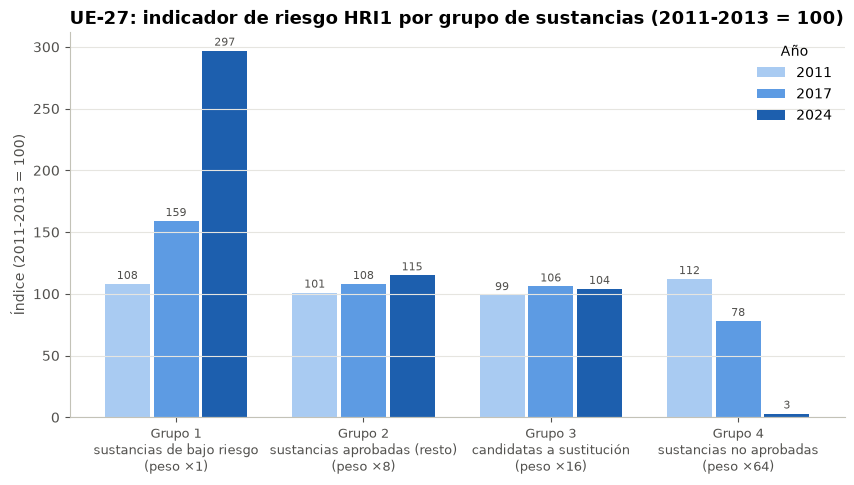

In [27]:
import numpy as np

fig, ax = plt.subplots(figsize=(10, 5))
posiciones = np.arange(len(riesgo_grupos))
ancho = 0.26
azules = ["#a9cbf2", "#5d9be3", "#1d5fae"]   # escala de un solo color: de claro (2011) a oscuro (2024)
for i, (año, color) in enumerate(zip([2011, 2017, 2024], azules)):
    valores = riesgo_grupos[f"indice_{año}"]
    ax.bar(posiciones + (i - 1) * ancho, valores, width=ancho - 0.02, color=color, label=str(año))
    for x, v in zip(posiciones + (i - 1) * ancho, valores):
        ax.text(x, v + 4, f"{v:.0f}", ha="center", fontsize=8, color="#52514e")
etiquetas = [f"{g.split(':')[0]}\n{g.split(': ')[1]}\n(peso ×{p})" for g, p in
             zip(riesgo_grupos["grupo_riesgo"], riesgo_grupos["ponderacion"])]
ax.set_xticks(posiciones, etiquetas, fontsize=9)
ax.set_title("UE-27: indicador de riesgo HRI1 por grupo de sustancias (2011-2013 = 100)")
ax.set_ylabel("Índice (2011-2013 = 100)")
ax.grid(axis="x", visible=False)
ax.legend(title="Año", loc="upper right")
guardar_grafico(fig, "09_riesgo_por_grupo")

In [28]:
ranking_riesgo = ejecutar("10_ranking_reduccion_riesgo")
ranking_riesgo

**Consulta `10_ranking_reduccion_riesgo`**
```sql
-- Pregunta 5. ¿Qué países han reducido más el indicador de riesgo?
-- Último año publicado de cada país (muchos años son confidenciales).
WITH ultimo_dato AS (
    SELECT codigo_pais, MAX(año) AS año
    FROM fact_riesgo_pesticidas
    WHERE indice_2015_2017 IS NOT NULL AND codigo_pais <> 'EU27_2020'
    GROUP BY codigo_pais
)
SELECT
    RANK() OVER (ORDER BY r.indice_2015_2017)  AS ranking,
    p.pais,
    r.año                                       AS año_dato,
    r.indice_2015_2017,
    CASE WHEN r.indice_2015_2017 <= 50 THEN 'Sí' ELSE 'No' END AS cumple_objetivo_2030
FROM fact_riesgo_pesticidas AS r
JOIN ultimo_dato            AS u ON u.codigo_pais = r.codigo_pais AND u.año = r.año
JOIN dim_pais               AS p ON p.codigo_pais = r.codigo_pais
ORDER BY ranking;
```

,ranking,pais,año_dato,indice_2015_2017,cumple_objetivo_2030
0,1,Países Bajos,2023,23.0,Sí
1,2,Luxemburgo,2023,31.0,Sí
2,3,Eslovenia,2023,33.0,Sí
3,4,España,2023,35.0,Sí
4,4,Irlanda,2023,35.0,Sí
5,6,Italia,2023,36.0,Sí
6,7,Croacia,2023,37.0,Sí
7,8,Rumanía,2023,38.0,Sí
8,9,Portugal,2023,42.0,Sí
9,10,Alemania,2023,51.0,No


In [29]:
print("Países con dato publicado:", len(ranking_riesgo))
print("Países que ya están en 50 o menos:", (ranking_riesgo["cumple_objetivo_2030"] == "Sí").sum())

Países con dato publicado: 16
Países que ya están en 50 o menos: 9


**Respuesta a la pregunta 5**

- **Con el indicador oficial, el objetivo ya se ha alcanzado**: la UE-27 está en **42** en 2023 (−58 % respecto a 2015-2017)
  y España en **35** (−65 %). De los 16 países que publican el dato, 9 ya están en 50 o menos.
- **Con los kilos vendidos, la UE y España están lejos**: respecto a 2015-2017, las ventas han bajado un 14,8 % en la UE (18 países)
  y un 20,6 % en España. Al ritmo actual llegarían a 2030 con una reducción del **24,4 %** (UE) y del **33,2 %** (España),
  lejos del −50 %. Para cumplirlo en kilos, España tendría que reducir sus ventas un **7,4 % cada año**.
- La diferencia se explica por la **retirada de sustancias peligrosas**: el índice del grupo 4 (no aprobadas, peso ×64) cae de 112 a 3,
  mientras que el de las sustancias de bajo riesgo casi se triplica (de 108 a 297). Es decir, se venden **casi los mismos kilos, pero de productos menos peligrosos**.

## 6. Limitaciones de los datos

In [30]:
cobertura = ejecutar("12_cobertura_datos_pesticidas")
cobertura

**Consulta `12_cobertura_datos_pesticidas`**
```sql
-- Limitaciones. Años con dato publicado y años confidenciales del total de
-- ventas de pesticidas por país (14 años posibles: 2011-2024).
SELECT
    p.pais,
    COUNT(v.kg)                                          AS años_con_dato,
    SUM(CASE WHEN v.nota LIKE '%c%' THEN 1 ELSE 0 END)   AS años_confidenciales,
    14 - COUNT(v.kg)                                     AS años_sin_dato,
    CASE WHEN COUNT(v.kg) = 14 THEN 'completa' ELSE 'incompleta' END AS serie
FROM dim_pais AS p
LEFT JOIN fact_ventas_pesticidas AS v
     ON v.codigo_pais = p.codigo_pais AND v.codigo_pesticida = 'TOTAL'
WHERE p.es_agregado = 0
GROUP BY p.pais
HAVING COUNT(v.kg) < 14
ORDER BY años_con_dato;
```

,pais,años_con_dato,años_confidenciales,años_sin_dato,serie
0,Estonia,1,13,13,incompleta
1,Bulgaria,4,5,10,incompleta
2,Malta,5,9,9,incompleta
3,Luxemburgo,9,0,5,incompleta
4,Polonia,10,4,4,incompleta
5,Chipre,11,3,3,incompleta
6,Eslovaquia,11,3,3,incompleta
7,Suecia,11,3,3,incompleta
8,Croacia,12,0,2,incompleta


In [31]:
# Resumen de notas en las tablas de hechos
resumen = []
for tabla in ["fact_ventas_pesticidas", "fact_riesgo_pesticidas", "fact_fertilizantes",
              "fact_balance_nutrientes", "fact_sau", "fact_pct_ecologica"]:
    df = pd.read_sql(f"SELECT nota FROM {tabla} WHERE codigo_pais <> 'EU27_2020'", conexion)
    resumen.append({
        "tabla": tabla,
        "filas": len(df),
        "confidenciales (c)": df["nota"].str.contains("c", na=False).sum(),
        "estimadas (e)": df["nota"].str.contains("e", na=False).sum(),
        "provisionales (p)": df["nota"].str.contains("p", na=False).sum(),
    })
pd.DataFrame(resumen)

,tabla,filas,confidenciales (c),estimadas (e),provisionales (p)
0,fact_ventas_pesticidas,11477,1982,0,0
1,fact_riesgo_pesticidas,351,143,0,0
2,fact_fertilizantes,742,0,84,24
3,fact_balance_nutrientes,459,0,76,0
4,fact_sau,378,0,9,1
5,fact_pct_ecologica,370,0,22,2


- **Pesticidas sin total UE y con datos confidenciales.** Eurostat no publica el total de la UE y 9 países tienen años confidenciales
  o sin dato en el total de ventas (Estonia solo publica 1 de 14 años). El "total UE" de este análisis es la suma de los **18 países con serie completa**,
  así que no incluye, por ejemplo, Polonia. En España, los molusquicidas y los reguladores del crecimiento son confidenciales casi todos los años.
- **Indicador oficial de riesgo**: muchos países no publican su valor (confidencial), aunque sí cuentan en el total UE-27, que llega hasta 2023.
- **Fertilizantes**: el total oficial UE-27 llega hasta 2019; Chipre no tiene datos desde 2020 y Malta en 2020-2021. Los datos de España de 2022-2024 son provisionales.
- **Balance de nitrógeno**: el total UE-27 solo llega a 2014; siete países no publican desde 2015 o antes y casi todos los valores antiguos son estimados.
- **Kilos vendidos ≠ kilos aplicados**: las ventas de un año pueden usarse al año siguiente o en usos no agrícolas, y los kg no reflejan la toxicidad.
- La proyección a 2030 es una **extrapolación aritmética**, no una predicción.

## 7. Conclusiones

- **Pesticidas:** las ventas en kg de la UE (18 países) y de España **se mantienen estables hasta 2021 y bajan desde 2022**. En 2024 están
  un 15,3 % y un 18,1 % por debajo de 2011. Los fungicidas siguen siendo el grupo principal y los insecticidas crecen.
- **El objetivo del −50 % depende de cómo se mida:** con el indicador oficial de uso y riesgo, la UE (42) y España (35) **ya lo han alcanzado**.
  En kilos, al ritmo actual, la reducción en 2030 sería del 24,4 % (UE) y del 33,2 % (España). El riesgo baja porque se han retirado
  las sustancias más peligrosas, no porque se usen muchos menos pesticidas.
- **Fertilizantes:** el consumo de nitrógeno y fósforo cae en 2022 y en 2024 la UE usa un 10 % menos de nitrógeno y un 12,8 % menos de fósforo que en 2011.
  España usa menos por hectárea que la media de la UE, pero su consumo de nitrógeno vuelve a subir.
- **Exceso de nitrógeno:** Países Bajos (136,8 kg/ha) es el gran caso de exceso; España (37,9 kg/ha) está por debajo de la media.
- **Ecológico y pesticidas:** entre países no hay una relación clara; los países mediterráneos tienen mucho ecológico y muchos kg por hectárea,
  en parte por el azufre y el cobre. Correlación no es causalidad.

In [32]:
conexion.close()